# W08A A · 모형·해석·변환·적합도

2026-10-19 · 실제5주차 W05A/W05B 복습. 설명용 실제자료와 각 연습문항의 합성자료를 구별합니다.
한 행은 직원 한 명이 아니라 부서 한 곳입니다. 원래 값은 긍정 응답 비율(%), 값의 변화는 %p입니다.
이번 표기는 p=설명변수 수, k=p+1=절편 포함 계수 수, q=제약 수입니다.

A: `rating ~ complaints + privileges`; B: `rating ~ complaints + learning`; F: `rating ~ .`(나머지 여섯 변수).
수업의 주 모형은 B입니다. A와 B는 서로 중첩되지 않으며, 둘 중 하나와 F의 비교는 별도로 구별합니다.

[함수 목적·입출력·정의 바로가기](https://github.com/lunalab-ai/regre/blob/2026-fall-w08a/src/w08a-review-api.md)

먼저 코드의 결과를 예상하고 실행 후 이유를 적으세요. 연습의 빈칸·의도 오류는 문제문에 있으며 실행 셀은 TODO입니다.
기본 전체 실행 성공은 문제풀이 완료를 뜻하지 않습니다. 온라인R·R Colab·로컬R 중 한 환경을 선택하면 됩니다.
별도 성적 과제·제출기한은 없습니다. R/QMD를 다운로드하면 data폴더를 함께 보관하세요.

CPU R런타임에서 이 노트북만 단독 실행할 수 있습니다. 준비 셀은 검증된 고정 버전의 공통 함수를 받고, 다시 실행할 때 다운로드한 파일의 무결성을 확인합니다.


In [ ]:
helper_ref <- "ba38f5fe7e1c75ac78eac6ff5c33b962c63c8541"
locations <- c("labs/student/w08a/data","../../labs/student/w08a/data")
found <- locations[file.exists(file.path(locations,"mlr-inference.R"))]
data_dir <- if(length(found)) found[1] else file.path(path.expand("~"),".cache","regre",helper_ref)
dir.create(data_dir,recursive=TRUE,showWarnings=FALSE)
options(timeout=120)
target <- file.path(data_dir,"mlr-inference.R")
if(!file.exists(target)) {
  download.file("https://raw.githubusercontent.com/lunalab-ai/regre/ba38f5fe7e1c75ac78eac6ff5c33b962c63c8541/src/mlr-inference.R",target,mode="wb")
  cat("Downloaded fixed helper: mlr-inference.R\n")
} else cat("Reusing helper cache; checking bytes: mlr-inference.R\n")
if(unname(tools::md5sum(target))!="220bb19be470b1d35e13f48ed562ab96") stop("Helper checksum mismatch; inspect the named file before restarting.")
source(target)
target <- file.path(data_dir,"mlr-tools.R")
if(!file.exists(target)) {
  download.file("https://raw.githubusercontent.com/lunalab-ai/regre/ba38f5fe7e1c75ac78eac6ff5c33b962c63c8541/src/mlr-tools.R",target,mode="wb")
  cat("Downloaded fixed helper: mlr-tools.R\n")
} else cat("Reusing helper cache; checking bytes: mlr-tools.R\n")
if(unname(tools::md5sum(target))!="7cbdffbadc83fa5e4fe5addf82d9add3") stop("Helper checksum mismatch; inspect the named file before restarting.")
source(target)
cat(R.version.string,"\n")
demo_d <- datasets::attitude
demo_fit_A <- lm(rating ~ complaints+privileges, data=demo_d)
demo_fit_B <- lm(rating ~ complaints+learning, data=demo_d)
demo_fit_F <- lm(rating ~ ., data=demo_d)
demo_models <- list(A=demo_fit_A,B=demo_fit_B,F=demo_fit_F)
demo_scaling <- mlr_scaling(demo_d)
demo_new <- data.frame(complaints=mean(demo_d$complaints),learning=mean(demo_d$learning))
demo_intervals <- mlr_interval_comparison(demo_fit_B,demo_new)
cat("Data: attitude, same 30 complete department rows; original levels in percent.
")
print(data.frame(model=names(demo_models), formula=vapply(demo_models,function(m) paste(deparse(formula(m)),collapse=" "),character(1)), n=30,
                 p=vapply(demo_models,function(m) length(coef(m))-1L,integer(1)),
                 k=vapply(demo_models,function(m) length(coef(m)),integer(1))))


## 설명 예제 · 실제30부서

모형식·행·단위를 먼저 읽고 표의 의미를 설명합니다. 연습문항의 합성 숫자와 구별합니다.

In [ ]:
demo_summary <- do.call(rbind,lapply(names(demo_models),function(label) {
  m <- demo_models[[label]]
  data.frame(model=label,SSE=deviance(m),df=df.residual(m),R2=summary(m)$r.squared,adjusted_R2=summary(m)$adj.r.squared)
}))
print(demo_summary)
print(demo_scaling$coefficients)
plot(fitted(demo_fit_B),demo_scaling$fitted_original_units$standardized,
     pch=19,col="#087f8c",xlab="Original fitted rating (%)",ylab="Restored fitted rating (%)",
     main="Same 30 rows: changing coordinates preserves fitted values")
abline(0,1,col="#c35c2a",lwd=2)


![기존 W05B의 개념 비교 그림](https://raw.githubusercontent.com/lunalab-ai/regre/ba38f5fe7e1c75ac78eac6ff5c33b962c63c8541/course/notion/w05b/assets/a03-scales.png)

기존 수업의 설명 그림이며 연습문항 답안표가 아닙니다. [원본 PNG](https://raw.githubusercontent.com/lunalab-ai/regre/ba38f5fe7e1c75ac78eac6ff5c33b962c63c8541/course/notion/w05b/assets/a03-scales.png) · [원본 위치](https://github.com/lunalab-ai/regre/blob/ba38f5fe7e1c75ac78eac6ff5c33b962c63c8541/course/notion/w05b/assets/a03-scales.png)
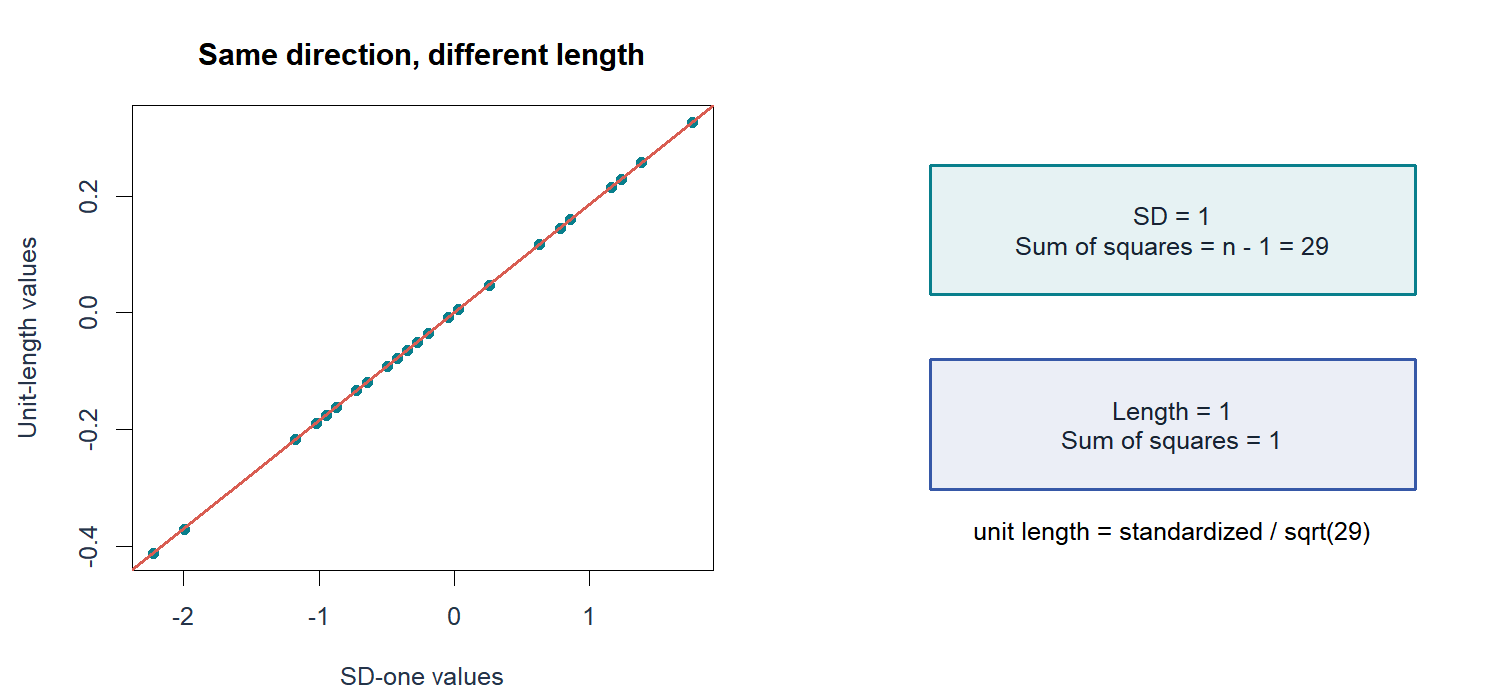

## Q43 · 행마다 같은 계수를 적용하기

합성자료 네 행에서 설명변수는 두 개이다. 절편을 포함한 주어진 식은 $\hat y=5+2x_1-x_2$이며 모든 변수는 이 문제의 점수 단위이다. `cbind`는 열을 나란히 묶고, `%*%`는 행렬 곱, `drop`은 결과의 불필요한 차원 표시를 없앤다. 함수 이름을 새로 작성할 필요는 없다.

빈칸을 채우고 $X$의 크기와 출력되는 네 예측값을 쓰시오. 관측 수와 계수 수가 코드의 어느 방향에 해당하는지도 설명하시오.

```r
x1 <- c(1, 2, 3, 4)
x2 <- c(1, 4, 1, 4)
X <- cbind(1, x1, x2)
b <- c(5, 2, -1)
prediction <- drop(X %*% ____)
print(prediction)
```

In [ ]:
# Q43 TODO: 직접 완성하고 실행하세요.

## Q44 · 잔차분산의 분모 고치기

절편과 설명변수 두 개를 포함한 완전계수 OLS 모형에서 $n=12$, $k=3$은 **절편까지 포함한 계수 수**, $SSE=18$이다. 다음 코드는 실행되지만 단순회귀의 자유도를 잘못 사용한다. 틀린 한 줄을 고치고 잔차 자유도와 오차분산 추정값을 구하시오.

```r
n <- 12
k <- 3
SSE <- 18
residual_df <- n - 2
s2 <- SSE / residual_df
print(c(df = residual_df, s2 = s2))
```

In [ ]:
# Q44 TODO: 직접 완성하고 실행하세요.

## Q45 · 정규방정식의 작은 계산

절편을 포함한 합성자료의 모형행렬은 $X^\mathsf TX=\operatorname{diag}(4,4,4)$, $X^\mathsf Ty=(40,8,-4)^\mathsf T$를 만족한다. 완전계수이므로 정규방정식의 각 좌표는 $4\hat\beta_j=(X^\mathsf Ty)_j$이다. `*`는 좌표별 곱, `sum`은 합이다.

빈칸을 채워 세 계수와 $x_0=(1,2,1)^\mathsf T$에서의 예측값을 구하시오. 긴 역행렬 계산은 필요하지 않다.

```r
Xty <- c(40, 8, -4)
b <- Xty / ____
x0 <- c(1, 2, 1)
prediction <- sum(x0 * b)
print(b)
print(prediction)
```

In [ ]:
# Q45 TODO: 직접 완성하고 실행하세요.

## Q46 · X 중심화 뒤 절편

주어진 예측식은 $\hat y=5+2x_1-x_2$이고 설명변수 평균은 $(5,2)$이다. 반응변수는 그대로 두고 $x_1^c=x_1-5$, $x_2^c=x_2-2$로 바꾼다. 아래에서 `b[-1]`은 두 기울기이며 `centers`는 원래 설명변수 평균이다.

빈칸을 채우고 새 절편과 두 기울기를 쓰시오. 같은 관측의 예측값이 왜 유지되는지도 설명하시오.

```r
b <- c(5, 2, -1)
centers <- c(5, 2)
new_intercept <- b[1] + sum(b[-1] * ____)
print(c(new_intercept, b[-1]))
```

In [ ]:
# Q46 TODO: 직접 완성하고 실행하세요.

## Q47 · 새 자료를 자기 평균으로 바꾼 오류

학습 자료에서 $\bar x=10$, $s_x=2$, $\bar y=50$, $s_y=10$으로 표준화했고, 적합한 표준화 식은 $\hat z_y=0.6z_x$이다. 새 입력은 원단위로 $(12,14)$이다. 다음 코드는 실행되지만 새 자료의 평균·표준편차로 다른 좌표계를 만든다.

틀린 줄을 학습 때의 기준으로 고치고 새 $z_x$와 원단위 예측값 두 개를 구하시오. 새 자료의 평균을 다시 계산하면 안 되는 이유를 쓰시오. `mean`과 `sd`는 입력한 벡터의 평균과 표본 표준편차를 계산한다.

```r
new_x <- c(12, 14)
z_new <- (new_x - mean(new_x)) / sd(new_x)
predicted_z_y <- 0.6 * z_new
predicted_y <- 50 + 10 * predicted_z_y
print(z_new)
print(predicted_y)
```

In [ ]:
# Q47 TODO: 직접 완성하고 실행하세요.

## Q48 · 표준편차 1과 길이 1의 출력

합성벡터 $x=(2,4,6)$을 사용한다. `sd`는 분모 $n-1$인 표본 표준편차, `length`는 원소 수, `sqrt`는 양의 제곱근이다. 출력되는 세 값을 순서대로 쓰고 두 변환의 차이를 설명하시오.

```r
x <- c(2, 4, 6)
z <- (x-mean(x)) / sd(x)
u <- z / sqrt(length(x)-1)
print(c(sd_z = sd(z), squared_length_z = sum(z^2),
        squared_length_u = sum(u^2)))
```

In [ ]:
# Q48 TODO: 직접 완성하고 실행하세요.

## Q49 · 잡음의 SD가 두 배일 때

같은 완전계수 설계행렬 X에서 OLS 계수의 분산은 $\sigma^2$에 비례한다. 어떤 계수의 기존 분산 추정값이0.04이고 오차의 **표준편차**를 두 배로 바꾼 상황에서, 같은 X의 분산비례식을 적용하여 새 분산 추정값을 계산한다. 출력 두 값과 그 이유를 쓰시오. 계수 추정값 자체가 반드시 두 배가 된다는 뜻인지도 설명하시오.

```r
v_old <- 0.04
sigma_factor <- 2
v_new <- sigma_factor^2 * v_old
print(c(variance = v_new, SE = sqrt(v_new)))
```

In [ ]:
# Q49 TODO: 직접 완성하고 실행하세요.

## Q50 · 평균모형 대비 오차 감소

절편을 포함한 동일 자료의 OLS 적합에서 $SST=80$, $SSE=20$이다. 평균만 예측하는 기준에 대한 $R^2$를 구하는 빈칸을 채우고, 결과를 정확히 한 문장으로 해석하시오. 관측을 맞힌 비율로 해석하지 않는다.

```r
SST <- 80
SSE <- 20
R2 <- 1 - SSE / ____
print(R2)
```

In [ ]:
# Q50 TODO: 직접 완성하고 실행하세요.

## Q51 · 수정 R²에서 빠진 절편

동일한 완전계수·절편 포함 OLS 자료에서 $n=12$, **설명변수 수** $p=2$, $SSE=18$, $SST=66$이다. 다음 수정 $R^2$ 계산은 잔차 자유도를 잘못 사용한다. 한 줄을 수정하고 올바른 값과 두 분모의 의미를 쓰시오.

```r
n <- 12
p <- 2
SSE <- 18
SST <- 66
adjusted_R2 <- 1 - (SSE/(n-p)) / (SST/(n-1))
print(adjusted_R2)
```

In [ ]:
# Q51 TODO: 직접 완성하고 실행하세요.

## Q52 · 변수 추가 후 두 지표 읽기

같은10개 관측과 같은 반응변수에서 절편 포함 축소모형과 중첩 완전모형을 적합했다. 축소모형의 설명변수 수는1, 완전모형은3이며 $SST=100$, SSE는 각각40과36이다. 출력되는 R²·수정 R²를 쓰고, 어느 지표가 왜 증가 또는 감소했는지 설명하시오. 이 두 수치만으로 미래 예측 우열을 확정할 수 있는지도 답하시오.

```r
n <- 10
SST <- 100
p <- c(1, 3)
SSE <- c(40, 36)
R2 <- 1-SSE/SST
adj <- 1-(SSE/(n-p-1))/(SST/(n-1))
print(data.frame(model=c("reduced","full"), R2=R2, adjusted_R2=adj))
```

In [ ]:
# Q52 TODO: 직접 완성하고 실행하세요.

## APP01 · 같은 모형에서 입력과 출력 연결

이 활동은 Q55·Q59의 실제자료 적용이며 60문항에 추가되는 독립 문항이 아닙니다.
[누적 앱 W08A](https://lunalab-ai.github.io/regre/apps/w08a/)의 **W08A 다중회귀 복습** 탭을 여세요.
1. 실제30부서의 A/B/F 식과 p·k·잔차자유도를 확인하고 B→F의 비교가 중첩인지 설명합니다. A/B와 구별합니다.
2. B의 평균 조건에서 confidence와 prediction을 바꾸기 **전** 중심과 폭의 변화를 예상하고 실행 뒤 관찰값·이유를 기록합니다.
3. 신뢰수준 또는 complaints 중 하나만 바꾸고, 나머지를 고정한 비교를 기록합니다. 각 변수의 범위 안이라는 사실만으로 공동 관측 범위의 지지를 보장하지 않음을 설명합니다.
4. [앱 편집기](https://lunalab-ai.github.io/regre/apps/w08a/edit/index.html)에서 `W08A_APP01` 표식이 있는 `selectInput("w8_kind",...)` 줄의 `selected="confidence"`를 `selected="prediction"`으로 바꾸고 Run합니다. 기본 선택과 폭 표시가 연결되는지 확인합니다. 다른 줄은 바꾸지 않습니다.
5. 입력 `w8_kind` → 두 구간 표에서 행 선택 → 폭 표시의 연결을 말로 설명합니다. 아래 `selected_kind` 한 줄을 바꾸어 같은 계산을 R에서도 확인할 수 있습니다.

학습 기록: 예상 / 바꾼 조건 하나 / 유지한 조건 / 실제 관찰 / 수식에서 바뀐 항 / 해석의 한계.


In [ ]:
selected_kind <- "confidence"
activity_rows <- mlr_interval_comparison(demo_fit_B,demo_new,level=.95)
activity_selected <- activity_rows[activity_rows$kind==selected_kind,,drop=FALSE]
print(activity_selected[c("kind","fit","lower","upper","width")])

stopifnot(nrow(demo_d)==30,all(complete.cases(demo_d)),df.residual(demo_fit_B)==27,df.residual(demo_fit_F)==23)
stopifnot(abs(summary(demo_fit_B)$r.squared-.708015195853)<1e-10,max(abs(demo_scaling$fitted_original_units$standardized-fitted(demo_fit_B)))<1e-9)
stopifnot(abs(mlr_nested_f(demo_fit_B,demo_fit_F)$F-.528702821078)<1e-10,nrow(demo_intervals)==2,demo_intervals$width[2]>demo_intervals$width[1])